<a href="https://colab.research.google.com/github/manar-amar/DQL/blob/main/gaussian_kl_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧠 Tutorial 1.2: Basics on Probability distributions, KL Divergence
---
## 📘 1. Gaussian Distribution and KL Divergence
This notebook discusses two core ideas in probability and machine learning:
- The **Gaussian (Normal) Distribution**, one of the most fundamental continuous distributions.
- The **Kullback–Leibler (KL) Divergence**, a measure of difference between two probability distributions.

We will explore:
- How Gaussian parameters affect shape and spread of the distribution.
- Univariate and Multivariate Gaussian distributions.
- How to compute, visualize, and interpret KL divergence between different gaussian distributions.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


## 🏗️ 3. The Gaussian Distribution
A Gaussian (Normal) distribution is defined as:

$$
p(x) = \frac{1}{\sqrt{2\pi\sigma^2}} \exp\left( -\frac{(x-\mu)^2}{2\sigma^2} \right)
$$

- **μ (mu):** mean — the center of the distribution  
- **σ (sigma):** standard deviation — controls the spread


**TO-DO**
1. Define a distribution of intergers lying between a range [-r,r]
2. Determine the normal distribution for the spread of this values with mean  **μ** and standard deviation  **σ**
3. Compare the distributions with different values of mean and standard deviation
4. State your findings in few sentences!!

In [3]:
import numpy as np
import matplotlib.pyplot as plt

In [4]:
x = np.linspace(-10, 10, 400)
params = [(0, 1), (0, 2), (2, 1)]
def gaussian_pdf_from_scratch(x, mu, sigma):
    """
    Computes the probability density function (PDF) of a Gaussian distribution from scratch.
    """

    return (1 / (np.sqrt(2 * np.pi) * sigma)) * np.exp(
        -((x - mu) ** 2) / (2 * sigma ** 2)
    )


In [6]:
print(np.sqrt(25))

5.0


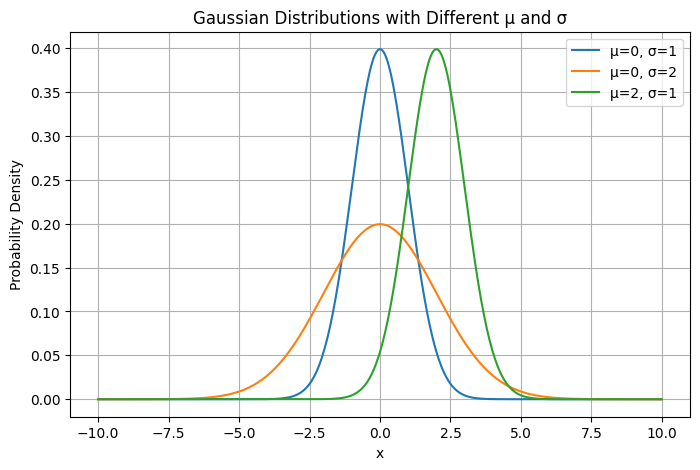

In [7]:
plt.figure(figsize=(8, 5))

for mu, sigma in params:
    y = gaussian_pdf_from_scratch(x, mu, sigma)
    plt.plot(x, y, label=f"μ={mu}, σ={sigma}")

plt.title("Gaussian Distributions with Different μ and σ")
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.legend()
plt.grid()
plt.show()

In [8]:
print("Observations:")
print("1. Changing the mean (mu) shifts the distribution horizontally.")
print("2. Increasing the standard deviation (sigma) makes the distribution wider and flatter.")
print("3. Decreasing the standard deviation makes the distribution narrower and taller.")

Observations:
1. Changing the mean (mu) shifts the distribution horizontally.
2. Increasing the standard deviation (sigma) makes the distribution wider and flatter.
3. Decreasing the standard deviation makes the distribution narrower and taller.


### 🧩 Probability Computation
1. Compute the probability such that a standard normal variable $X \sim N(0,1)$ falls between -1 and 1.

In [10]:
from scipy.stats import norm

probability = norm.cdf(1) - norm.cdf(-1)

print("Probability:", probability)

Probability: 0.6826894921370859


## 📊 4. Sampling and Fitting

**TO-DO**
1. Draw random variables from normal distributions
2. Plot the histogram of the data
3. Plot the fitted Gaussian distribution on the data

Estimated mean: 2.93
Estimated std: 1.98


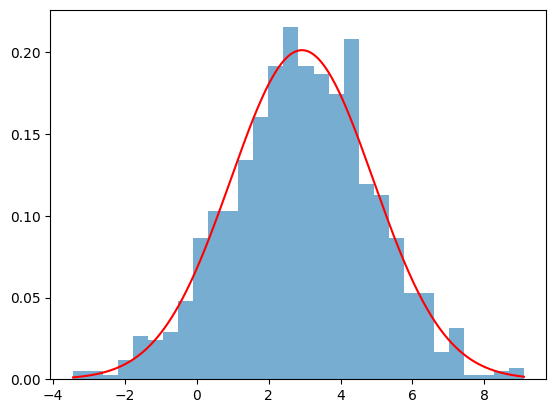

In [13]:
# Generate random data
data = np.random.normal(loc=3, scale=2, size=1000)
mu_est = np.mean(data)
sigma_est = np.std(data)

print(f"Estimated mean: {mu_est:.2f}")
print(f"Estimated std: {sigma_est:.2f}")
plt.hist(data, bins=30, density=True, alpha=0.6, label="Data")

x_fit = np.linspace(min(data), max(data), 400)

y_fit = gaussian_pdf_from_scratch(
    x_fit, mu_est, sigma_est
)

plt.plot(x_fit, y_fit, 'r', label="Fitted Gaussian")

Estimated mean: 3.04, std: 1.96


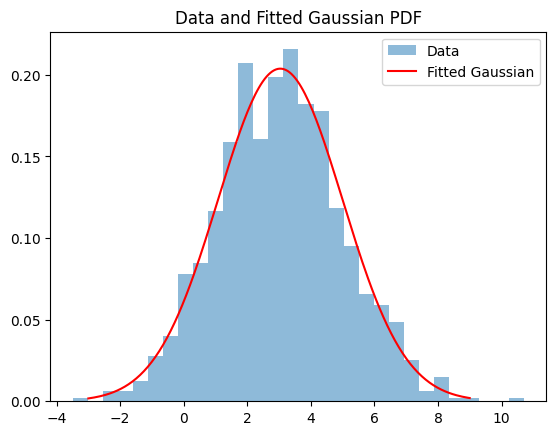

In [ ]:
## TO-DO



plt.legend()
plt.title("Data and Fitted Gaussian PDF")
plt.show()

## 🌀 5. Multivariate Gaussian

Until now, we have been working with a one-dimensional Gaussian distribution, also known as a univariate Gaussian. We will explore the cases with distributions with d dimensions.

**TO-DO**
1. Define the function to compute multivariate gaussian distribution from scratch.
2. Use mean and covariance.

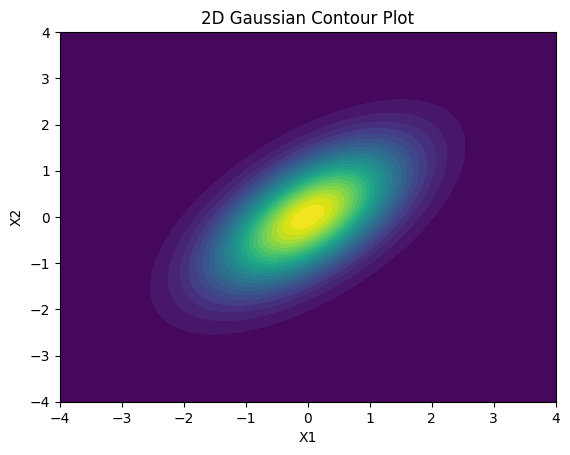

In [14]:
import numpy as np

def multivariate_gaussian_pdf(x, mean, cov):

    d = len(mean)

    diff = x - mean

    exponent = -0.5 * diff.T @ np.linalg.inv(cov) @ diff

    denominator = np.sqrt(
        ((2 * np.pi) ** d) * np.linalg.det(cov)
    )

    return np.exp(exponent) / denominator


# Define mean and covariance
mean = np.array([0, 0])

cov = np.array([
    [1, 0.6],
    [0.6, 1]
])

# Create grid
x1 = np.linspace(-4, 4, 100)
x2 = np.linspace(-4, 4, 100)

X1, X2 = np.meshgrid(x1, x2)

Z = np.zeros_like(X1)

for i in range(len(x1)):
    for j in range(len(x2)):
        point = np.array([X1[i, j], X2[i, j]])
        Z[i, j] = multivariate_gaussian_pdf(
            point, mean, cov
        )

plt.contourf(X1, X2, Z, levels=30, cmap='viridis')


plt.title("2D Gaussian Contour Plot")
plt.xlabel("X1")
plt.ylabel("X2")
plt.show()

## ⚖️ 6. KL Divergence
The **Kullback–Leibler Divergence** measures how one probability distribution differs from another:
$$
D_{KL}(P || Q) = \int p(x) \log \frac{p(x)}{q(x)} dx
$$

Properties:
It’s not symmetric: $D_{KL}(P || Q) \neq D_{KL}(Q || P)$.

In [17]:
def kl_gaussian(mu0, sigma0, mu1, sigma1):

    kl = np.log(sigma1 / sigma0) + (
        sigma0**2 + (mu0 - mu1)**2
    ) / (2 * sigma1**2) - 0.5

    return kl

kl = kl_gaussian(0, 1, 2, 1)
print(f"KL(N(0,1) || N(2,1)) = {kl:.3f}")

KL(N(0,1) || N(2,1)) = 2.000


### 🧠 Exercise 2: Explore KL Sensitivity

**TO-DO**
1. Analyze the sensitivity of KL by varying the mean of the distribution.
2. Set a distribution p and compute the KL divergence against q with the changing mean value.

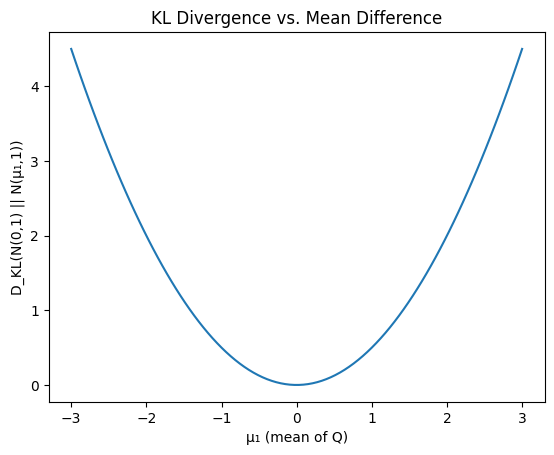

In [18]:

# Define P = N(0,1)
mu0 = 0
sigma0 = 1

# Define different mean values for Q
mus = np.linspace(-3, 3, 100)

# Compute KL divergence for each mean
kl_values = []

for mu in mus:
    kl = kl_gaussian(mu0, sigma0, mu, 1)
    kl_values.append(kl)
plt.plot(mus, kl_values)
plt.title("KL Divergence vs. Mean Difference")
plt.xlabel("μ₁ (mean of Q)")
plt.ylabel("D_KL(N(0,1) || N(μ₁,1))")
plt.show()

KL Divergence increases when the difference between the means of two Gaussian distributions increases. When both distributions have the same mean and standard deviation, KL Divergence equals zero.

## 🧩 7. Monte Carlo Approximation of KL Divergence

**TO-DO**

1. Formulate the Monte Carlo Approximation to compute KL-divergence between two distribution?

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def kl_monte_carlo(mu0, sigma0, mu1, sigma1, n_samples=100000):

    # Sample from distribution P
    samples = np.random.normal(mu0, sigma0, n_samples)

    # Log probability of P
    log_p = -np.log(sigma0 * np.sqrt(2 * np.pi)) \
            - ((samples - mu0) ** 2) / (2 * sigma0 ** 2)

    # Log probability of Q
    log_q = -np.log(sigma1 * np.sqrt(2 * np.pi)) \
            - ((samples - mu1) ** 2) / (2 * sigma1 ** 2)

    # Monte Carlo approximation
    return np.mean(log_p - log_q)

approx_kl = kl_monte_carlo(0, 1, 2, 1)
print(f"Monte Carlo KL ≈ {approx_kl:.3f}")

Monte Carlo KL ≈ 2.001


**TO-DO**

1. Show instances where KL-divergence fails. Explain the tractable and intractable case !!
2. Can you think of any approximations to compute KL divergence in such intractable cases?

Analytic KL (Gaussian vs Gaussian): 0.4431
Monte Carlo KL (Gaussian vs Gaussian): 0.4428
Monte Carlo KL (Gaussian vs Mixture): 0.9448


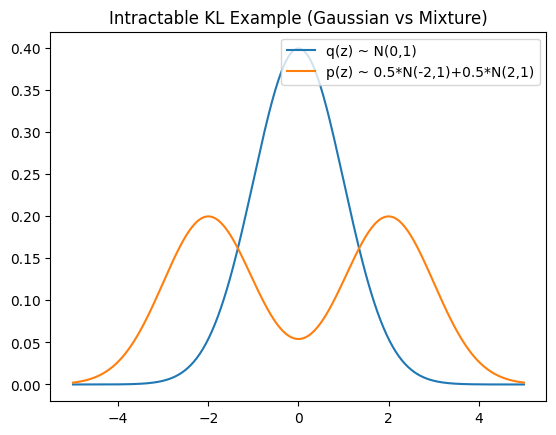

In [4]:
import torch
import torch.distributions as dist
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(0)

# 1. Tractable case: Gaussian vs Gaussian

q = dist.Normal(0, 1)
p = dist.Normal(1, 2)

# Analytic KL
analytic_kl = dist.kl_divergence(q, p)

print(f"Analytic KL (Gaussian vs Gaussian): {analytic_kl.item():.4f}")

# Monte Carlo approximation
samples = q.sample((100000,))

log_q = q.log_prob(samples)
log_p = p.log_prob(samples)

kl_mc = (log_q - log_p).mean()

print(f"Monte Carlo KL (Gaussian vs Gaussian): {kl_mc.item():.4f}")


# 2. Intractable case: Gaussian vs Mixture of Gaussians

# Define mixture distribution
mixture = dist.Categorical(torch.tensor([0.5, 0.5]))

components = dist.Normal(
    torch.tensor([-2.0, 2.0]),
    torch.tensor([1.0, 1.0])
)

p_mixture = dist.MixtureSameFamily(mixture, components)

# Log probability of mixture
def log_prob_mixture(z):
    return p_mixture.log_prob(z)

# q(z) = Normal(0,1)
samples = q.sample((100000,))

log_q = q.log_prob(samples)
log_p_mix = log_prob_mixture(samples)

kl_estimate = (log_q - log_p_mix).mean()

print(f"Monte Carlo KL (Gaussian vs Mixture): {kl_estimate.item():.4f}")


# 3. Visualization

xs = torch.linspace(-5, 5, 300)

q_vals = torch.exp(q.log_prob(xs))
p_vals = torch.exp(p_mixture.log_prob(xs))

plt.plot(xs.numpy(), q_vals.numpy(), label='q(z) ~ N(0,1)')
plt.plot(xs.numpy(), p_vals.numpy(),
         label='p(z) ~ 0.5*N(-2,1)+0.5*N(2,1)')

plt.legend()
plt.title("Intractable KL Example (Gaussian vs Mixture)")
plt.show()


KL divergence can be computed analytically for two Gaussian distributions using a closed-form formula. However, for more complex distributions such as Gaussian mixtures, an analytical solution may not be available. In these cases, Monte Carlo sampling provides a numerical approximation of KL divergence.

**TO-DO**

1. Compute the KL divergence between two Multivariate Gaussian distributions

In [5]:
def kl_multivariate_gaussian(mu0, cov0, mu1, cov1):

    d = len(mu0)

    cov1_inv = np.linalg.inv(cov1)

    diff = mu1 - mu0

    term1 = np.trace(cov1_inv @ cov0)

    term2 = diff.T @ cov1_inv @ diff

    term3 = np.log(np.linalg.det(cov1) / np.linalg.det(cov0))

    return 0.5 * (term1 + term2 - d + term3)


mu0 = np.array([0, 0])
mu1 = np.array([1, 1])

cov0 = np.array([[1, 0], [0, 1]])
cov1 = np.array([[2, 0], [0, 2]])

kl = kl_multivariate_gaussian(mu0, cov0, mu1, cov1)

print("Multivariate KL Divergence:", kl)

Multivariate KL Divergence: 0.6931471805599453


## 1️⃣ Why Reparameterization?

We often want to optimize an expectation of the form:
$$ \nabla_\phi \mathbb{E}_{z \sim q_\phi(z)}[f(z)] $$

But if we sample \(z\) directly from \(q_\phi(z)\), gradients can't flow through the sampling operation.

💡 **Idea:** Express \(z\) as a deterministic function of a parameter-free noise variable $(\epsilon)$:
$$ z = \mu_\phi + \sigma_\phi \odot \epsilon, \quad \epsilon \sim \mathcal{N}(0, I) $$

Now, gradients can flow through $\mu_\phi$ and $\sigma_\phi$ via backpropagation.

## 2️⃣ Visualizing Gaussian Sampling vs Reparameterization

1. Will there be any change in the distribution after applying the repararmeterization trick? Visualize the distributions.
2. Define the reparametrization trick.

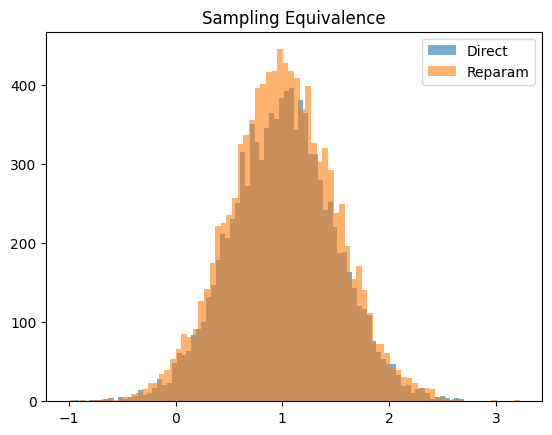

In [6]:
mu, sigma = 1.0, 0.5
n = 10000

# Direct sampling
direct = np.random.normal(mu, sigma, n)

# Reparameterized sampling
epsilon = np.random.normal(0, 1, n)

reparam = mu + sigma * epsilon
plt.hist(direct, bins=80, alpha=0.6, label='Direct')
plt.hist(reparam, bins=80, alpha=0.6, label='Reparam')
plt.legend()
plt.title('Sampling Equivalence')
plt.show()

** TO-DO**

1. What happens if we intend to calculate the gradients of random variable sampled from a normal distribution?
2. Compare it with the gradients calculated after using reparameterization trick.

In [10]:
import torch
torch.manual_seed(0)

# Parameters
mu = torch.tensor(1.0, requires_grad=True)
log_sigma = torch.tensor(0.5, requires_grad=True)

sigma = torch.exp(log_sigma)

# Reparameterized sample
epsilon = torch.randn(1000)

z = mu + sigma * epsilon

loss = z.mean() + z.pow(2).mean()

loss.backward()
print('Reparam grads -> mu:', mu.grad.item(), ' log_sigma:', log_sigma.grad.item())

# Naive sampling (breaks gradient flow)
# Parameters
mu2 = torch.tensor(1.0, requires_grad=True)
log_sigma2 = torch.tensor(0.5, requires_grad=True)

sigma2 = torch.exp(log_sigma2)

# Naive sampling
z2 = torch.normal(
    mean=mu2.detach().item(),
    std=sigma2.detach().item(),
    size=(1000,)
)

loss2 = z2.mean() + z2.pow(2).mean()

# No backward() for naive sampling

print('Naive grads -> mu:', mu2.grad, ' log_sigma:', log_sigma2.grad)

Reparam grads -> mu: 3.0953567028045654  log_sigma: 5.894877910614014
Naive grads -> mu: None  log_sigma: None


Reparameterization allows gradients to flow through random sampling by expressing the random variable as a deterministic function of the distribution parameters and an independent noise variable. Unlike direct sampling, this technique enables backpropagation and is widely used in Variational Autoencoders (VAEs).

** The END**

That's the wrap for the introductory tutorial. We will use these basic concepts in the following tutorials !!